In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent          # project folder (one level above notebooks/)
sys.path.insert(0, str(ROOT))     # so `from outputs_io import ...` works
FIG = ROOT / "figures"

import pandas as pd
import matplotlib.pyplot as plt
from outputs_io import load_results, load_predictions

In [2]:
df = load_results()

In [3]:
df.head()

,algorithm,params,p,k,mse,mae,n,n_resets_tune,n_resets_test,mean_gap_test
0,AAR,b=0.001,3.0,1,30.259879,4.415522,21044,NaN,NaN,NaN
1,AAR,b=0.01,3.0,2,30.271751,4.416412,21044,NaN,NaN,NaN
2,AAR,b=0.01,3.0,3,30.282101,4.417192,21044,NaN,NaN,NaN
3,AAR,b=0.01,3.0,4,30.290745,4.417842,21044,NaN,NaN,NaN
4,AAR,b=0.1,3.0,5,30.297231,4.418284,21044,NaN,NaN,NaN


In [4]:
df['k'].nunique()

9


=== k = 4 ===
       algorithm                  params       mae        mse
21           AAR                b=0.0001  4.379091  29.393151
57         ARCOR  r=1e-08, q=1.5, R_B=25  1.640115   4.389912
93         AROWR                r=0.0001  4.379091  29.393151
129       CR-RLS          r=0.8, T0=2880  1.606212   4.474271
165        LASER       b=1e-08, c=0.0001  1.279582   2.766014
201          RLS                   r=0.8  1.604033   4.463822
219  persistence                          1.731006   5.365077
228    yesterday                          1.928022   6.495810


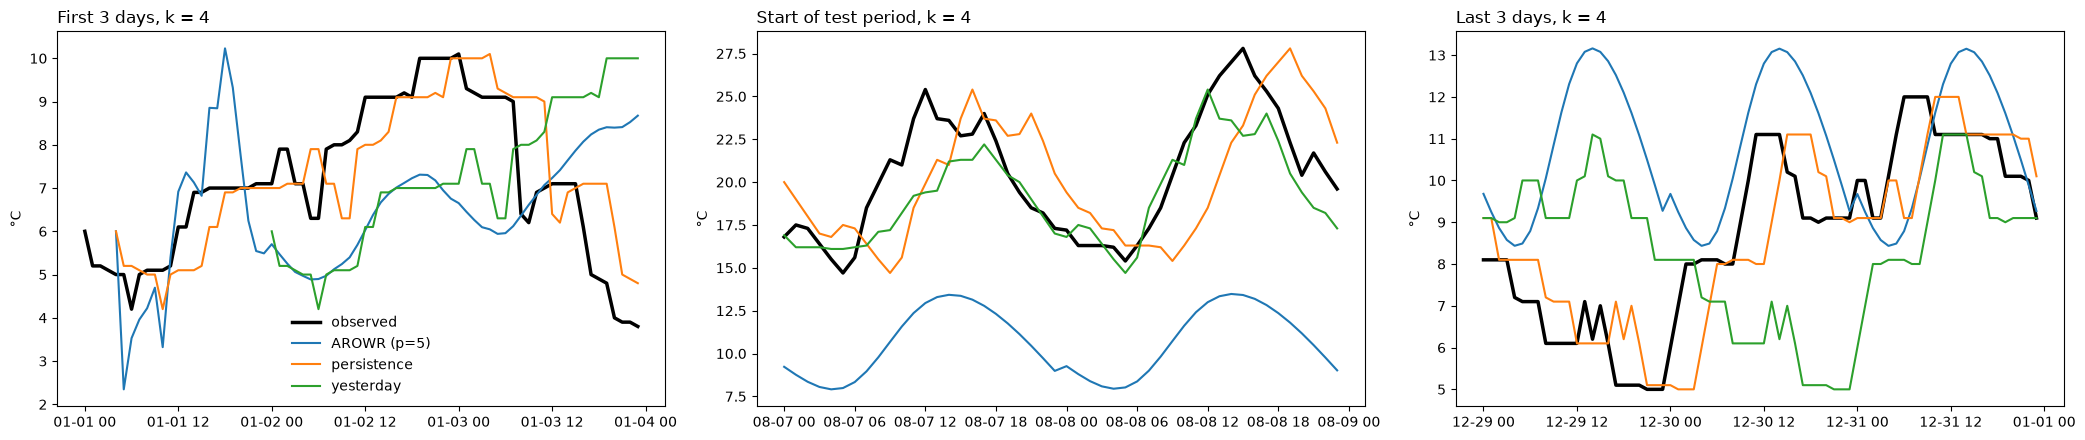


=== k = 5 ===
       algorithm                  params       mae        mse
22           AAR                b=0.0001  4.379451  29.398093
58         ARCOR  r=1e-08, q=1.5, R_B=25  1.840459   5.533491
94         AROWR                r=0.0001  4.379451  29.398093
130       CR-RLS            r=0.8, T0=48  1.781593   5.379209
166        LASER       b=1e-08, c=0.0001  1.435163   3.451755
202          RLS                   r=0.8  1.771054   5.390788
220  persistence                          2.057413   7.437538
229    yesterday                          1.928022   6.495810


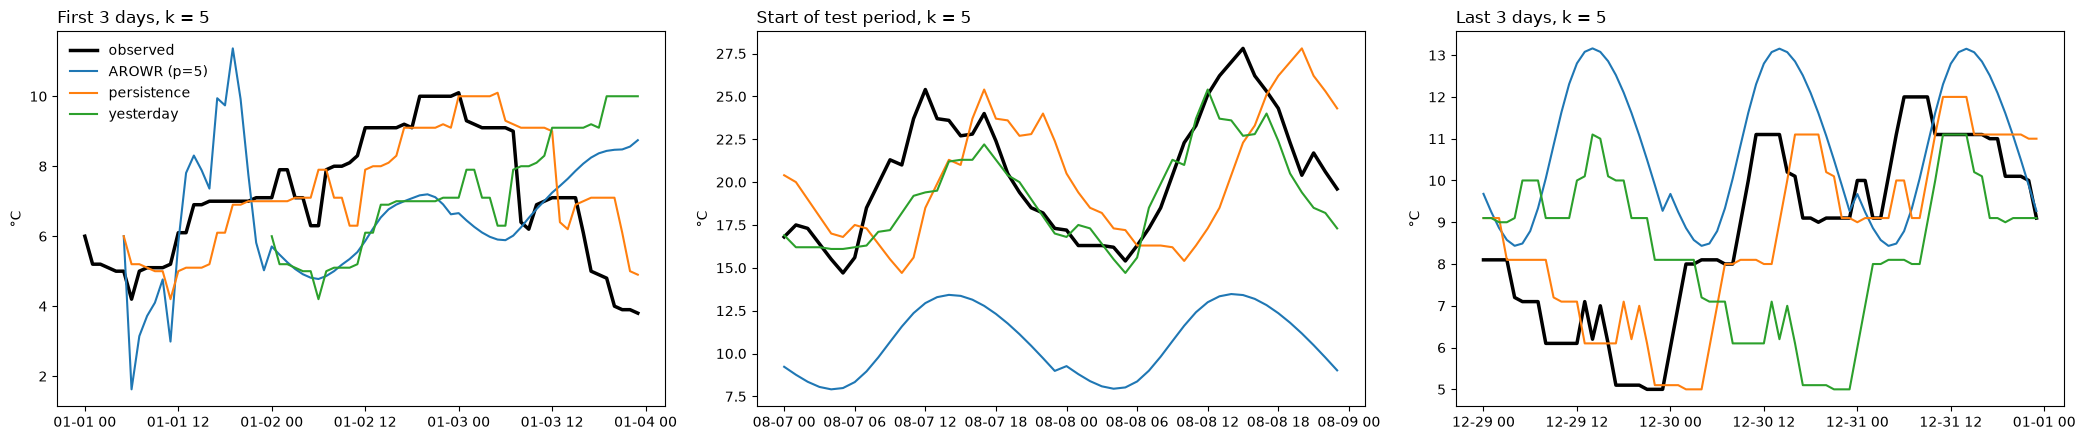


=== k = 6 ===
       algorithm              params       mae        mse
23           AAR            b=0.0001  4.379535  29.399348
59         ARCOR  r=1, q=1.5, R_B=50  1.756121   5.016821
95         AROWR            r=0.0001  4.379535  29.399348
131       CR-RLS        r=0.9, T0=72  1.767655   5.367194
167        LASER      b=1e-05, c=0.1  1.548174   4.010328
203          RLS               r=0.8  1.880536   6.098552
221  persistence                      2.345590   9.528483
230    yesterday                      1.928022   6.495810


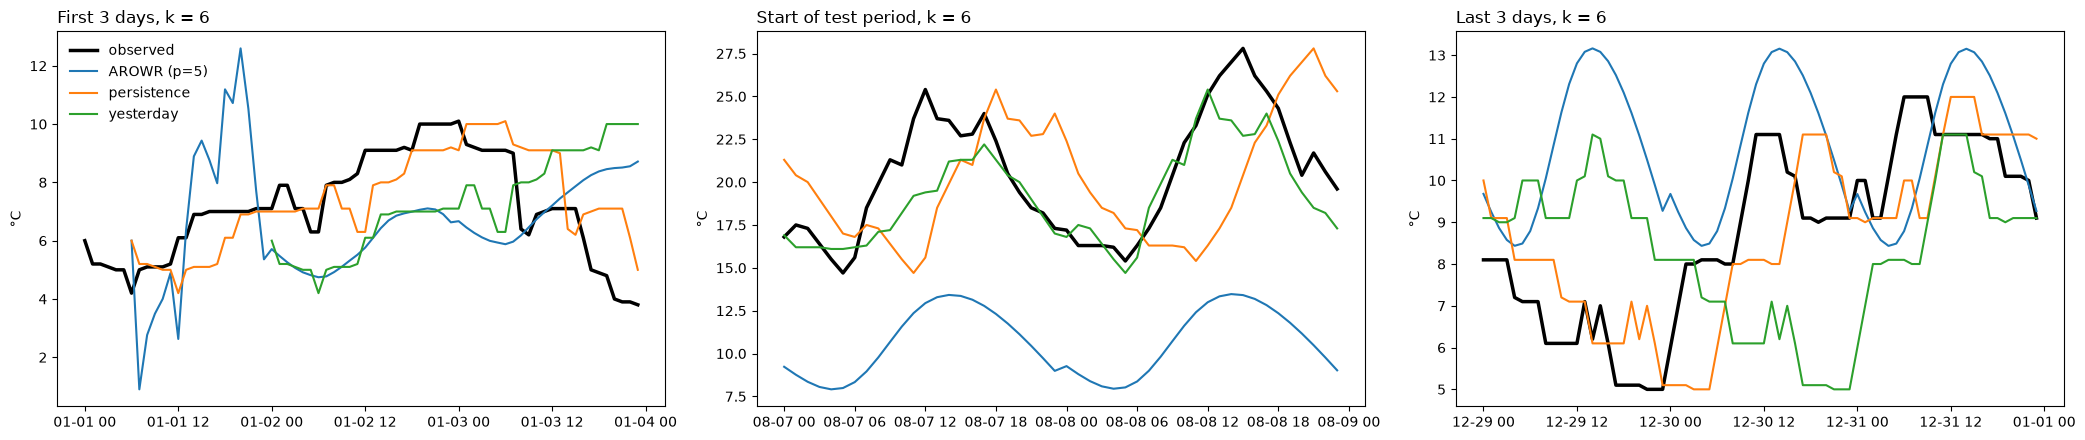


=== k = 7 ===
       algorithm            params       mae        mse
24           AAR          b=0.0001  4.379441  29.398154
60         ARCOR  r=1, q=2, R_B=50  2.042695   6.903808
96         AROWR          r=0.0001  4.379441  29.398154
132       CR-RLS    r=0.95, T0=168  1.841436   5.780291
168        LASER    b=0.0001, c=10  1.564495   4.084003
204          RLS             r=0.8  1.946272   6.540955
222  persistence                    2.599810  11.519078
231    yesterday                    1.928022   6.495810


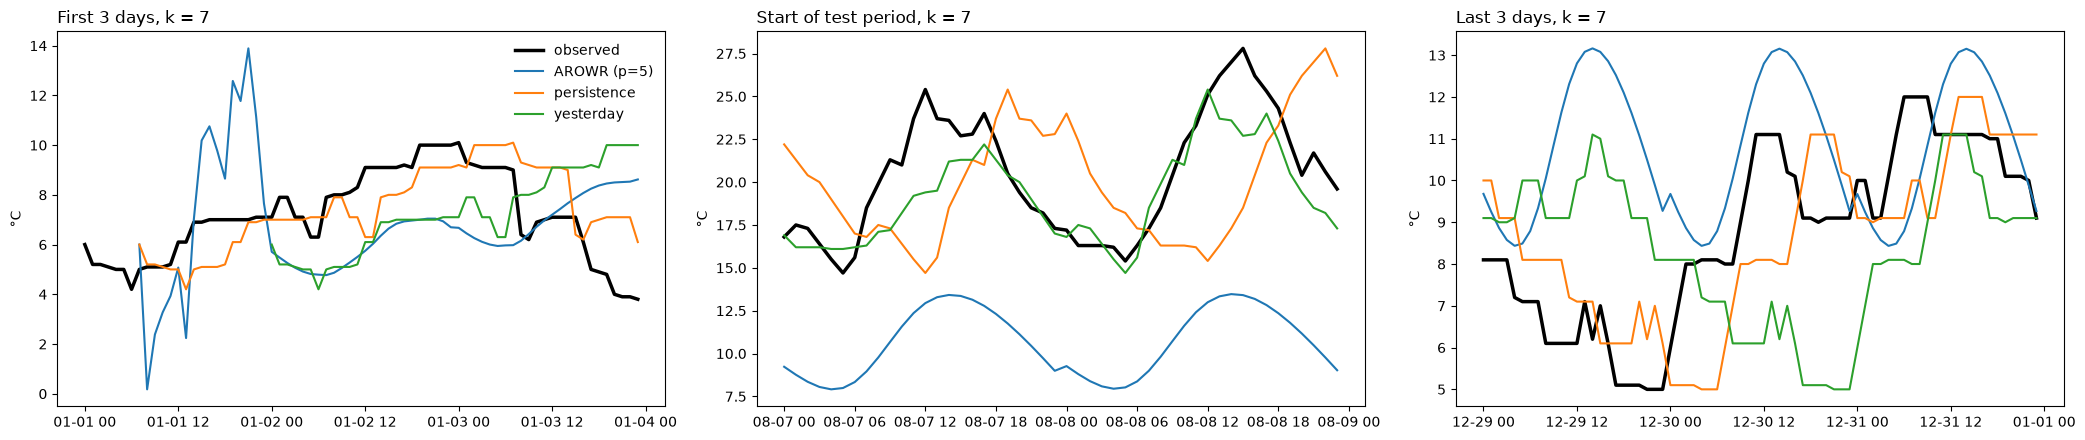


=== k = 8 ===
       algorithm             params       mae        mse
25           AAR           b=0.0001  4.379271  29.395868
61         ARCOR  r=1, q=2, R_B=100  2.055040   6.995997
97         AROWR           r=0.0001  4.379271  29.395868
133       CR-RLS     r=0.95, T0=168  1.870471   5.954082
169        LASER     b=0.0001, c=10  1.614251   4.336686
205          RLS             r=0.95  1.920654   6.293670
223  persistence                     2.809594  13.325026
232    yesterday                     1.928022   6.495810


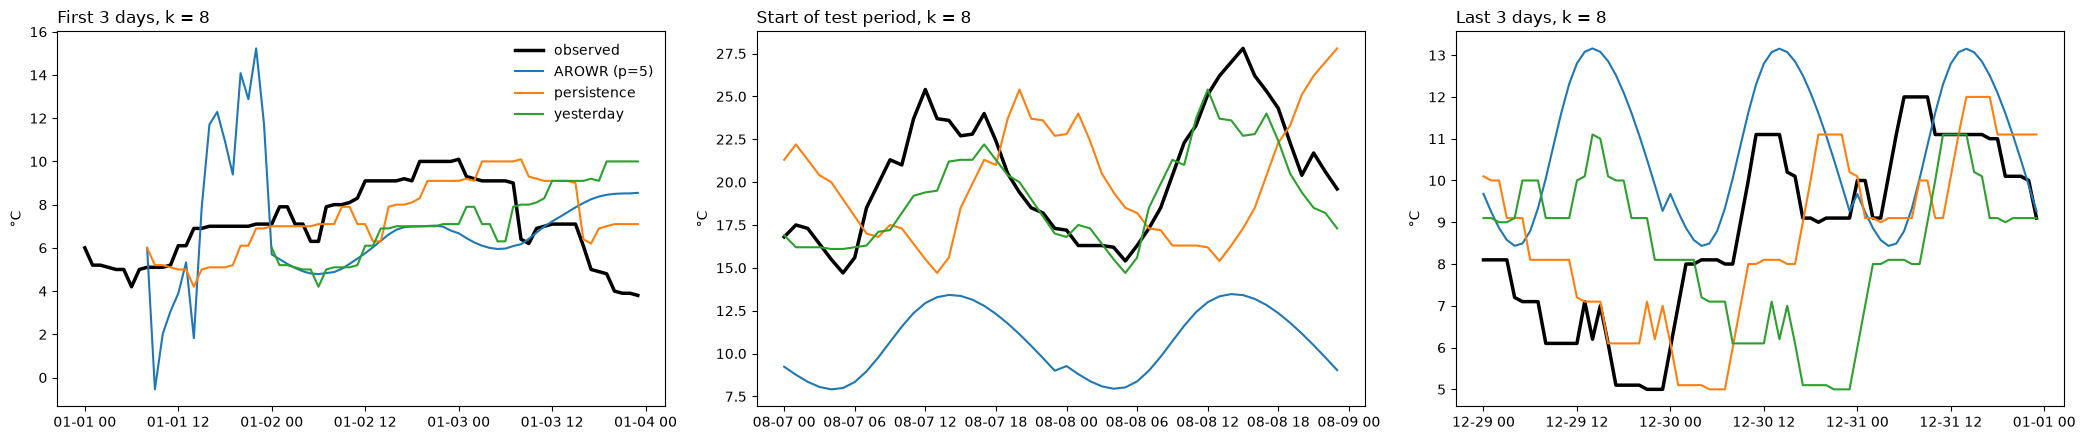


=== k = 9 ===
       algorithm               params       mae        mse
26           AAR              b=0.001  4.378946  29.393183
62         ARCOR  r=1, q=1.5, R_B=150  1.833241   5.527839
98         AROWR              r=0.001  4.378946  29.393183
134       CR-RLS       r=0.95, T0=168  1.888408   6.059237
170        LASER        b=0.001, c=10  1.652772   4.555507
206          RLS               r=0.95  1.900790   6.164678
224  persistence                       2.981924  14.866130
233    yesterday                       1.928022   6.495810


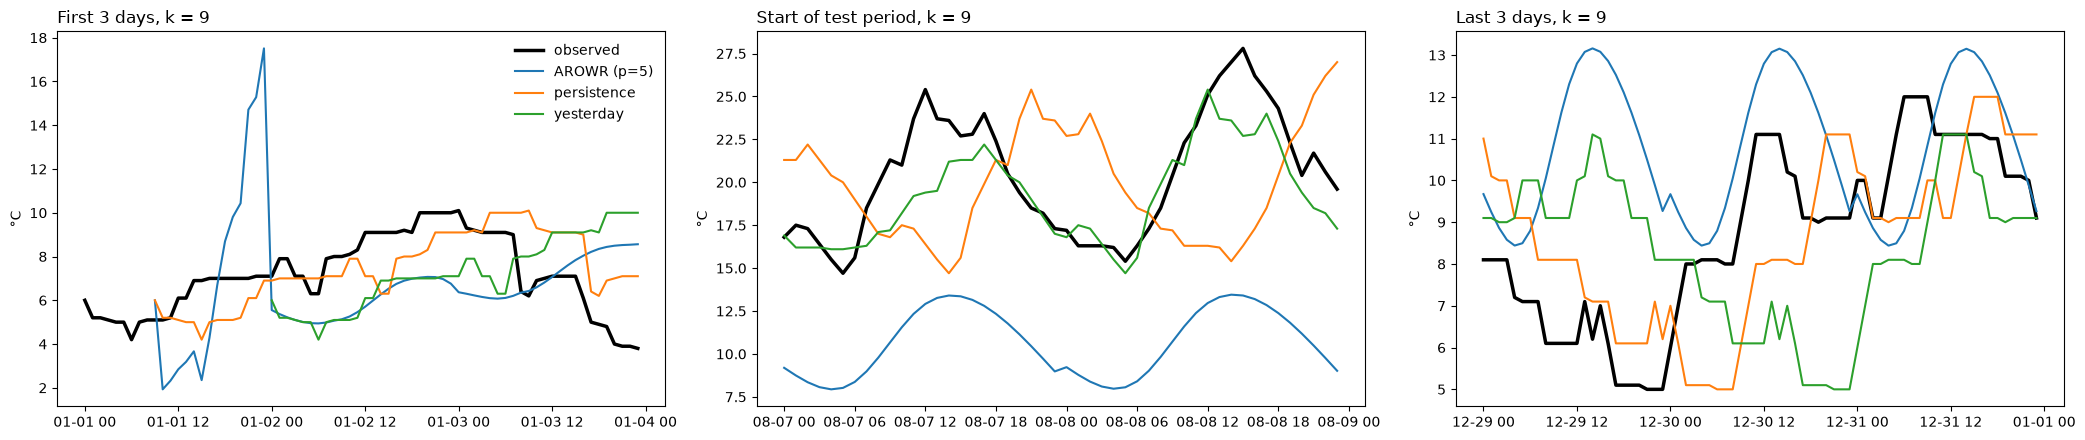

In [ ]:
res, pred = load_results(), load_predictions()
p = 5

windows = {"First 3 days": ("2020-01-01", "2020-01-04"),
           "Start of test period": ("2020-08-07", "2020-08-09"),
           "Last 3 days":  ("2022-12-29", "2023-01-01")}

for k in [4, 5, 6, 7, 8, 9, 10, 11, 12]:
    print(f"\n=== k = {k} ===")
    print(res[(res.k == k) & ((res.p == p) | res.p.isna())][["algorithm", "params", "mae", "mse"]])

    cols = {"obs": "observed", f"AROWR_k{k}_p{p}": f"AROWR (p={p})",
            f"persistence_k{k}": "persistence", f"yesterday_k{k}": "yesterday"}

    fig, axes = plt.subplots(1, 3, figsize=(21, 4.5))
    for ax, (title, (a, b)) in zip(axes, windows.items()):
        w = pred[(pred.time >= a) & (pred.time < b)]
        for c, lab in cols.items():
            ax.plot(w.time, w[c], label=lab, lw=2.5 if c == "obs" else 1.5,
                    color="black" if c == "obs" else None)
        ax.set_title(f"{title}, k = {k}", loc="left"); ax.set_ylabel("°C")
    axes[0].legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIG / f"k{k}_p{p}_first_last_days.png", dpi=150, bbox_inches="tight")
    fig.savefig(FIG / "seasonal_2021.png", dpi=150, bbox_inches="tight")
    plt.show()      # in a notebook, shows each chart as it's made
    plt.close(fig)  # stops 5 open figures piling up in memory

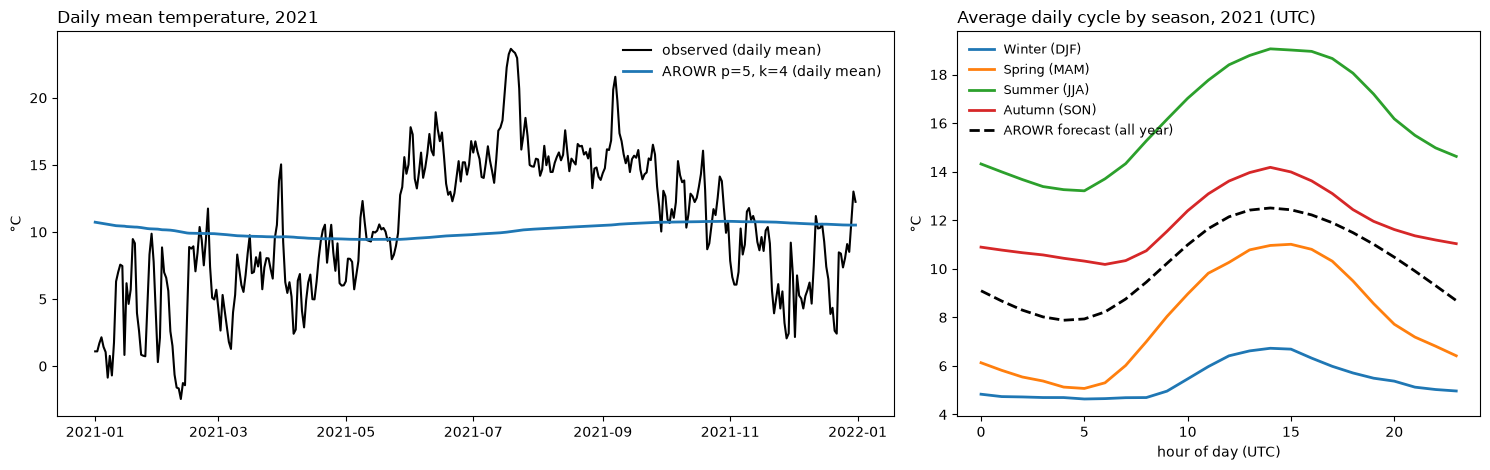

In [ ]:
pred = load_predictions().set_index("time")
yr, col = pred.loc["2021"], "AROWR_k4_p5"
daily = yr[["obs", col]].resample("D").mean()
seasons = {"Winter (DJF)": [12, 1, 2], "Spring (MAM)": [3, 4, 5],
           "Summer (JJA)": [6, 7, 8], "Autumn (SON)": [9, 10, 11]}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(daily.index, daily.obs, color="black", lw=1.5, label="observed (daily mean)")
axes[0].plot(daily.index, daily[col], lw=2, label="AROWR p=5, k=4 (daily mean)")
axes[0].set_title("Daily mean temperature, 2021", loc="left"); axes[0].set_ylabel("°C")
axes[0].legend(frameon=False)

for s, months in seasons.items():
    sub = yr[yr.index.month.isin(months)]
    axes[1].plot(sub.groupby(sub.index.hour)["obs"].mean(), lw=2, label=s)
axes[1].plot(yr.groupby(yr.index.hour)[col].mean(), "k--", lw=2, label="AROWR forecast (all year)")
axes[1].set_title("Average daily cycle by season, 2021 (UTC)", loc="left")
axes[1].set_xlabel("hour of day (UTC)"); axes[1].set_ylabel("°C")
axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig("figures/seasonal_2021.png", dpi=150, bbox_inches="tight")